# [B·D3] 공시 EDA

**목적:** 수집한 DART 공시의 구성을 파악하고, 정기공시에서 AI 언급이 언제·어디서 늘었는지 본다.

- 입력: `data/processed/project.db` 의 `documents`(공시 636건), `disclosure_chunks`(`rag/chunk.py` 결과)
- 출력: `data/processed/disclosure_counts_quarterly.csv` (B → A: 기업별·분기별 공시 건수, 탭 1 차트용)
- AI 언급은 `rag/chunk.py` 의 패턴 기준이다. (`AI`·`LLM` 은 앞뒤 영문자 제외, `docs/ai_level_guide.md` 부록 A-3)
- 기업 간 AI 언급 밀도 비교는 **사업보고서끼리** 한다. 분기보고서는 연혁·정관이 생략되어 섹션 구성이 다르다. (`docs/decisions.md`)

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import font_manager

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT))
from config import settings

# 한글 폰트: macOS AppleGothic → Windows Malgun Gothic → NanumGothic 순서로 있는 것 사용
fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ["AppleGothic", "Malgun Gothic", "NanumGothic"] if f in fonts), "sans-serif")
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 140)

con = sqlite3.connect(settings.DB_PATH)
docs = pd.read_sql("""
    SELECT d.doc_id, c.corp_name, d.title, d.published_date, d.report_type
    FROM documents d JOIN companies c USING(corp_code)
    WHERE d.source_type = 'disclosure'""", con, parse_dates=["published_date"])
ORDER = ["제일기획", "이노션", "플레이디", "인크로스", "KT나스미디어"]   # 기획안 순서: 종합대행 → 디지털대행 → 미디어렙
print(f"공시 {len(docs)}건, 기간 {docs.published_date.min():%Y-%m-%d} ~ {docs.published_date.max():%Y-%m-%d}")

공시 636건, 기간 2023-10-20 ~ 2026-10-02


## 1. 공시 유형 분포

In [2]:
by_type = (docs.pivot_table(index="corp_name", columns="report_type", values="doc_id", aggfunc="count", fill_value=0)
             .reindex(ORDER))
by_type = by_type[by_type.sum().sort_values(ascending=False).index]
by_type["합계"] = by_type.sum(axis=1)
by_type

report_type,거래소공시,지분공시,공정위공시,정기공시,기타공시,주요사항보고,합계
corp_name,,,,,,,
제일기획,110,29,24,13,5,1,182
이노션,75,47,22,14,7,1,166
플레이디,32,15,10,12,5,0,74
인크로스,60,8,19,13,9,0,109
KT나스미디어,54,8,18,14,9,2,105


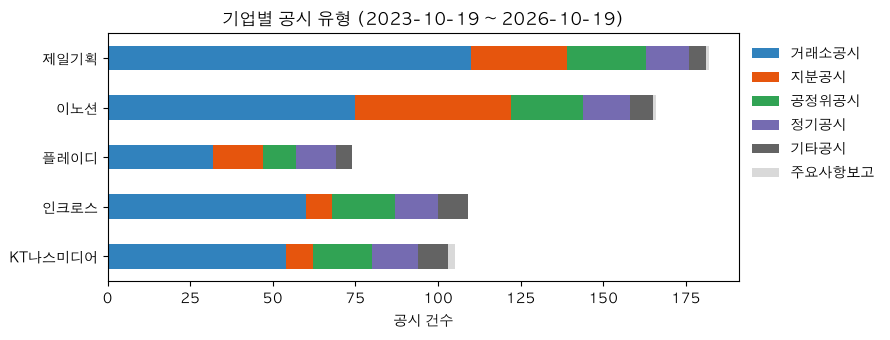

In [3]:
ax = by_type.drop(columns="합계").plot.barh(stacked=True, figsize=(9, 3.5), colormap="tab20c")
ax.invert_yaxis()
ax.set(xlabel="공시 건수", ylabel="", title="기업별 공시 유형 (2023-10-19 ~ 2026-10-19)")
ax.legend(bbox_to_anchor=(1, 1), frameon=False)
plt.tight_layout()

## 2. 기업별·분기별 공시 건수 (B → A 전달)

2023Q4(10-19부터)와 2026Q4(10-19까지)는 일부 기간만 들어간 분기다.

In [4]:
docs["quarter"] = docs.published_date.dt.to_period("Q").astype(str)
quarterly = (docs.pivot_table(index="quarter", columns="corp_name", values="doc_id", aggfunc="count", fill_value=0)
               [ORDER])
out = settings.DATA_DIR / "processed" / "disclosure_counts_quarterly.csv"
quarterly.to_csv(out, encoding="utf-8-sig")
print(f"[저장] {out.relative_to(ROOT)}")
quarterly.T

[저장] data/processed/disclosure_counts_quarterly.csv


quarter,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,2026Q4
corp_name,,,,,,,,,,,,,
제일기획,16,26,13,14,11,20,9,10,16,20,10,16,1
이노션,17,24,11,10,7,19,9,14,20,18,8,9,0
플레이디,4,10,2,3,3,17,6,2,4,14,6,3,0
인크로스,5,13,6,6,7,14,7,5,13,23,5,5,0
KT나스미디어,6,14,7,5,6,16,6,5,4,17,11,8,0


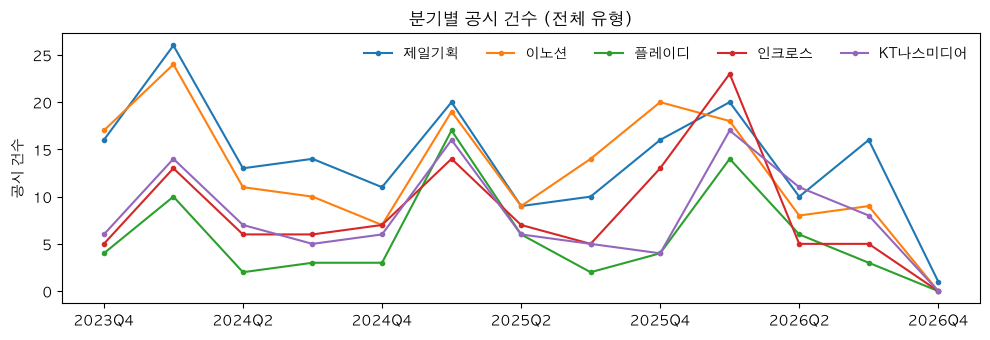

In [5]:
ax = quarterly.plot(figsize=(10, 3.5), marker="o", markersize=3)
ax.set(xlabel="", ylabel="공시 건수", title="분기별 공시 건수 (전체 유형)")
ax.legend(frameon=False, ncol=5)
plt.tight_layout()

## 3. 정기공시의 AI 언급 추이

- **AI 청크 수:** AI 용어가 1개 이상 있는 청크 수
- **AI 언급 밀도:** AI 청크 수 ÷ 전체 청크 수 (기획안 4절 지표)
- 정정 공시는 `rag/chunk.py` 에서 최신 판 하나만 남겼다.

In [6]:
reports = pd.read_sql("""
    SELECT c.corp_name, d.title, d.published_date,
           COUNT(*) AS chunks, SUM(k.ai_term_count > 0) AS ai_chunks, SUM(k.ai_term_count) AS ai_terms
    FROM disclosure_chunks k JOIN documents d USING(doc_id) JOIN companies c ON c.corp_code = k.corp_code
    GROUP BY k.doc_id""", con, parse_dates=["published_date"])
reports["kind"] = reports.title.str.replace(r"^\[[^\]]*\]", "", regex=True).str.split().str[0]
reports["period"] = reports.title.str.extract(r"\((\d{4}\.\d{2})\)")[0]
reports["density"] = (reports.ai_chunks / reports.chunks).round(3)

annual = (reports[reports.kind == "사업보고서"]
          .pivot_table(index="corp_name", columns="period", values="density").reindex(ORDER))
annual.columns = [f"FY{c[:4]}" for c in annual.columns]
print("사업보고서 AI 언급 밀도 (AI 청크 ÷ 전체 청크)")
annual

사업보고서 AI 언급 밀도 (AI 청크 ÷ 전체 청크)


,FY2023,FY2024,FY2025
corp_name,,,
제일기획,0.000,0.045,0.136
이노션,0.070,0.184,0.159
플레이디,0.067,0.133,0.273
인크로스,0.238,0.270,0.351
KT나스미디어,0.283,0.316,0.349


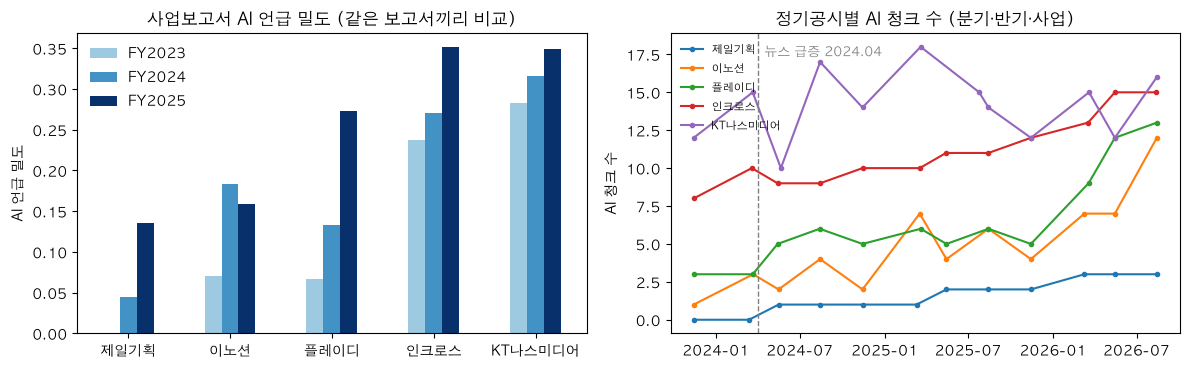

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
annual.plot.bar(ax=axes[0], rot=0, color=["#9ecae1", "#4292c6", "#08306b"])
axes[0].set(xlabel="", ylabel="AI 언급 밀도", title="사업보고서 AI 언급 밀도 (같은 보고서끼리 비교)")
axes[0].legend(frameon=False)

for name in ORDER:
    r = reports[reports.corp_name == name].sort_values("published_date")
    axes[1].plot(r.published_date, r.ai_chunks, marker="o", markersize=3, label=name)
axes[1].axvline(pd.Timestamp("2024-04-01"), color="gray", ls="--", lw=1)
axes[1].text(pd.Timestamp("2024-04-15"), axes[1].get_ylim()[1] * 0.92, "뉴스 급증 2024.04", color="gray", fontsize=9)
axes[1].set(ylabel="AI 청크 수", title="정기공시별 AI 청크 수 (분기·반기·사업)")
axes[1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()

## 4. 섹션별 AI 청크 (어디서 AI를 말하나)

In [8]:
sections = pd.read_sql("""
    SELECT c.corp_name, k.section, COUNT(*) AS ai_chunks
    FROM disclosure_chunks k JOIN companies c ON c.corp_code = k.corp_code
    WHERE k.ai_term_count > 0 GROUP BY 1, 2""", con)
sections["section"] = sections.section.str.replace(r"^[IVX]+\. [^>]+> ", "", regex=True)
by_section = sections.pivot_table(index="section", columns="corp_name", values="ai_chunks", fill_value=0)[ORDER]
by_section = by_section.loc[by_section.sum(axis=1).sort_values(ascending=False).index]
(by_section.div(by_section.sum()) * 100).round(0).astype(int).astype(str) + "%"

corp_name,제일기획,이노션,플레이디,인크로스,KT나스미디어
section,,,,,
7. 기타 참고사항,100%,75%,38%,67%,29%
6. 주요계약 및 연구개발활동,0%,0%,26%,17%,54%
2. 회사의 연혁,0%,22%,8%,0%,5%
1. 사업의 개요,0%,0%,15%,5%,5%
5. 정관에 관한 사항,0%,3%,0%,2%,7%
2. 주요 제품 및 서비스,0%,0%,0%,9%,0%
4. 매출 및 수주상황,0%,0%,13%,0%,0%


## 정리

**공시 구성**
- 5개사 공시 636건 중 거래소공시가 가장 많고, 분석에 쓰는 정기공시는 회사마다 12~14건이다.
- 분기별 공시 건수는 매년 1분기(사업보고서·주주총회 시즌)에 몰린다. 공시 건수 자체는 AI 이슈와 관계가 약하다.

**AI 언급 밀도 (사업보고서끼리 비교)**
- 5개사 모두 FY2023 → FY2025 사이 AI 언급 밀도가 올랐다. 이노션만 FY2024(0.18) → FY2025(0.16)로 조금 내렸다.
- 디지털 미디어렙(인크로스·KT나스미디어)이 FY2023부터 가장 높다(0.24~0.35). 대형 종합대행 제일기획은 FY2023 0 → FY2025 0.14로 가장 낮다.
- 플레이디는 FY2024 0.13 → FY2025 0.27로 두 배가 되었다.

**뉴스 급증(2024.04)과의 관계**
- 급증 직후 공시의 AI 청크가 뛰지는 않았다. KT나스미디어는 급증 전부터 이미 많았고, 플레이디·이노션은 2026년 보고서에서 크게 늘었다. → 반영 시차 분석(Day 5)의 근거.

**어디서 AI를 말하나**
- 제일기획의 AI 청크는 100% `7. 기타 참고사항`(시장 전망·수상 캠페인명)에 있고, 연구개발 섹션에는 없다.
- KT나스미디어는 54%가 `6. 주요계약 및 연구개발활동`에 있다. 이노션은 22%가 `회사의 연혁`(AI 조직 신설·MOU)이다.
- 언급 밀도는 "얼마나 말하나"일 뿐이다. 실제로 실행했는지는 Day 4 LLM 단계 분류(선언·계획·실행)로 확인한다.